# Predicción de casos confirmados de dengue mediante un modelo de Red Neuronal Convolucional 1D (CNN-1D) en la región Piura (2000–2025)
## ***Proyecto de Inteligencia Artificial***
### *Universidad Nacional Federico Villarreal*
### *Facultad de Ingeniería Electrónica e Informática*
### *Escuela Profesional de Ingeniería Informática*
Docente: Rodríguez Rodríguez, Ciro
Alumno: Pauca Muñoz, Fabrizzio Alejandro
Lima, Perú, 2026

El presente proyecto busca estimar la cantidad de casos confirmados de dengue en la región Piura basado en un historial de casos del dataset *Vigilancia Epidemiológica del Dengue* del MINSA como variable objetivo y utilizando variables climáticas (Open Meteo) y la temperatura superficial del mar (NOAA).

El objetivo es mejorar la capacidad preventiva de los centros médicos de esta región frente al Fenómeno El Niño.
La siguiente noticia explora la situación actual de Piura frente a este fenómeno [Piura acumula 15,716 casos de dengue y registra 17 muertes en 2026](https://nortesostenible.com/dengue-piura-15716-casos-17-muertes-2026/)

## Resumen de Construcción del Dataset df_final.csv

En los archivos de la carpeta Preprocesamiento se construyó el dataset final que se está empleando en este proyecto. El archivo base fue el dataset [*Vigilancia Epidemiológica del dengue*](https://www.datosabiertos.gob.pe/dataset/vigilancia-epidemiol%C3%B3gica-de-dengue) del MINSA, el cuál contempla todos los casos confirmados, probables y sospechosos, de los cuales solo se seleccionaron los casos confirmados (tipo_dx == 'C', 217,048 registros) de la región Piura en todo el periodo 2000 a 2025 para que el modelo pueda contemplar las anomalías generadas por el Fenómeno El Niño en los años 2017, 2023 y 2024; posteriomente se agruparon los casos según año y semanas, 52 semanas epidemiológicas en 25 años; de aquí se obtuvo el archivo **casos_dengue_piura_2000_2025_semanal** con 1352 filas.

El segundo dataset a integrar fue **clima_piura_2000_2025_semanal.csv** con 1356 filas, este se obtuvo utilizando la API de Open-Meteo [Open-Meteo](https://open-meteo.com/) para extraer datos meteorológicos (Temperatura y Precipitación) diarios utilizando coordenadas de la Estación Miraflores de la UNP; brindó las variables climáticas 'Precipitacion'(sumatoria diaria), 'Temp_Max' y 'Temp_Min'.

El tercer y último dataset a incorporar fue **temperatura_superficial_mar_piura_2000_2025_semanal.csv**; este también se obtuvo utilizando una API, la del NOAA [National Oceanic and Atmospheric Administration](https://www.cpc.ncep.noaa.gov/data/indices/), los datos extraídos corresponden a un archivo Fortran que contiene los registros de la temperatura superficial del mar peruano y las anomalías generadas por el Fenómeno El Niño; este dataset se utilizará para que el modelo pueda comprender las anomalías en las cantidades de casos confirmados de dengue generadas con el Fenómeno El Niño, puesto que los casos son mucho mayores en los años 2017, 2023 y 2024 usando las variables 'TSM_Nino12' y 'Anomalia_Nino12'

Finalmente, los tres datasets fueron integrados en el archivo intregacion_datasets.py donde se alinearon según el año y la semana epidemiológica del MINSA utilizando la función merge y dos reglas de imputación para este proyecto:

Regla A: Si el MINSA no reportó filas en una semana, hubo 0 casos confirmados
Regla B: Si alguna semana puntual no tuvo lectura satelital/climática, aplicamos forward/backward fill

Siguiendo estas reglas se obtuvo un dataset final de **1356 filas** y **8 columnas** guardado como df_final.csv

# Desarrollo del modelo

### Importación de librerías y dataset crudo

In [ ]:
# Ejecución en Google Colab 
# (Subir previamente el dataset df_final.csv al explorador de archivos de Colab)
import pandas as pd
import numpy as np

df_etl = pd.read_csv('df_final.csv').sort_values(['ano','semana']).reset_index(drop=True)

In [1]:
# Ejecución en entorno local
from pathlib import Path
import pandas as pd
import numpy as np

ruta_csv = next(
    (ruta / 'Datasets' / 'df_final.csv' for ruta in (Path.cwd(), *Path.cwd().parents)
      if (ruta / 'Datasets' / 'df_final.csv').is_file()), None
)
df_etl = pd.read_csv(ruta_csv).sort_values(['ano','semana']).reset_index(drop=True)

## Exploración Inicial de Dataset df_etl

In [2]:
print(f'Cantidad de Registros: {len(df_etl)}')
print(f'Dimensiones: {df_etl.shape}')
print("Se muestran los 10 registros más recientes del dataset")
display(df_etl.tail(10))
df_etl.info()

Cantidad de Registros: 1356
Dimensiones: (1356, 8)
Se muestran los 10 registros más recientes del dataset


,ano,semana,Casos_Confirmados,Precipitacion,Temp_Max,Temp_Min,TSM_Nino12,Anomalia_Nino12
1346,2025,44,6,7.7,30.37,18.63,21.3,0.1
1347,2025,45,10,12.2,30.17,18.69,21.3,-0.2
1348,2025,46,11,7.6,30.97,18.96,20.9,-0.8
1349,2025,47,8,5.0,29.90,18.57,21.4,-0.5
1350,2025,48,4,4.7,31.76,19.60,22.0,-0.1
1351,2025,49,3,0.0,31.66,19.36,22.1,-0.3
1352,2025,50,2,9.0,30.83,18.24,22.3,-0.3
1353,2025,51,3,1.9,31.86,19.66,22.4,-0.5
1354,2025,52,4,0.0,32.81,19.41,22.9,-0.4
1355,2025,53,3,0.0,32.08,19.30,22.7,-0.9


<class 'pandas.DataFrame'>
RangeIndex: 1356 entries, 0 to 1355
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ano                1356 non-null   int64  
 1   semana             1356 non-null   int64  
 2   Casos_Confirmados  1356 non-null   int64  
 3   Precipitacion      1356 non-null   float64
 4   Temp_Max           1356 non-null   float64
 5   Temp_Min           1356 non-null   float64
 6   TSM_Nino12         1356 non-null   float64
 7   Anomalia_Nino12    1356 non-null   float64
dtypes: float64(5), int64(3)
memory usage: 84.9 KB


Como se mencionó anteriormente, dataset tiene 1356 registros correspondientes a todas las semanas desde el año 2000 al 2025; todas las columnas utilizadas son numéricas, siendo ano y semana las variables identificadoras; la variable Casos_Confirmados actúa como variable objetivo y las variables meteorológicas servirán de variables predictoras.

## Preprocesamiento inicial

### Manejo de la estacionalidad cíclica
Se convertirán las semanas en seno y coseno para manejar la estacionalidad cíclica de cada año y así el modelo pueda entender que la semana 52/53 es contigua a la semana 1

In [3]:
df_etl['semana_sin'] = np.sin(2 * np.pi * df_etl['semana'] / 52.18)
df_etl['semana_cos'] = np.cos(2 * np.pi * df_etl['semana'] / 52.18)

## Manejo de la distribución asimétrica de la variable objetivo
Se suavizará la variable 'Casos_Confirmados' usando log predominante en el año 2017 y 2023 por los fenómenos acontecidos en estos años para que la gradiente no sea dominado por estos. La gráfica muestra la cantidad de casos confirmados por año, se observa que 2017 y 2023 muestran picos muy extremos de casos.

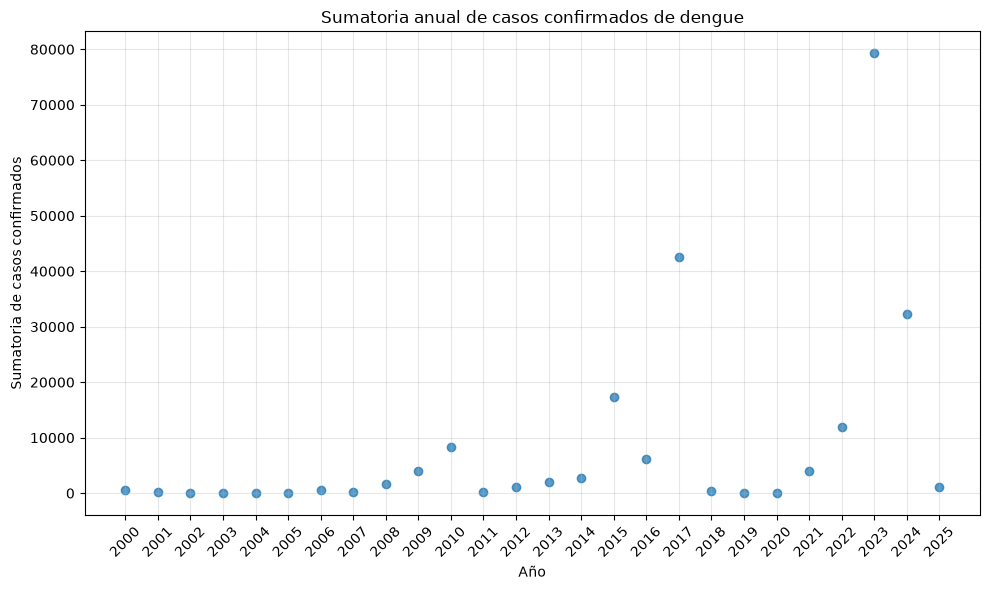

In [11]:
def cantidad_casos_anual(casos):
    import pandas as pd
    import matplotlib.pyplot as plt

    df_plot = df_etl[["ano", casos]].copy()

    df_plot["ano"] = pd.to_numeric(df_plot["ano"], errors="coerce")
    df_plot[casos] = pd.to_numeric(
        df_plot[casos], errors="coerce"
    )
    df_plot = df_plot.dropna(subset=["ano", casos])
    df_plot["ano"] = df_plot["ano"].astype(int)

    casos_por_ano = (
        df_plot.groupby("ano", as_index=False)[casos]
        .sum()
        .sort_values("ano").astype(int)
    )

    plt.figure(figsize=(10, 6))
    plt.scatter(
        casos_por_ano["ano"],
        casos_por_ano[casos],
        alpha=0.75
    )

    plt.title("Sumatoria anual de casos confirmados de dengue")
    plt.xlabel("Año")
    plt.ylabel("Sumatoria de casos confirmados")
    plt.xticks(casos_por_ano["ano"], rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
cantidad_casos_anual("Casos_Confirmados")

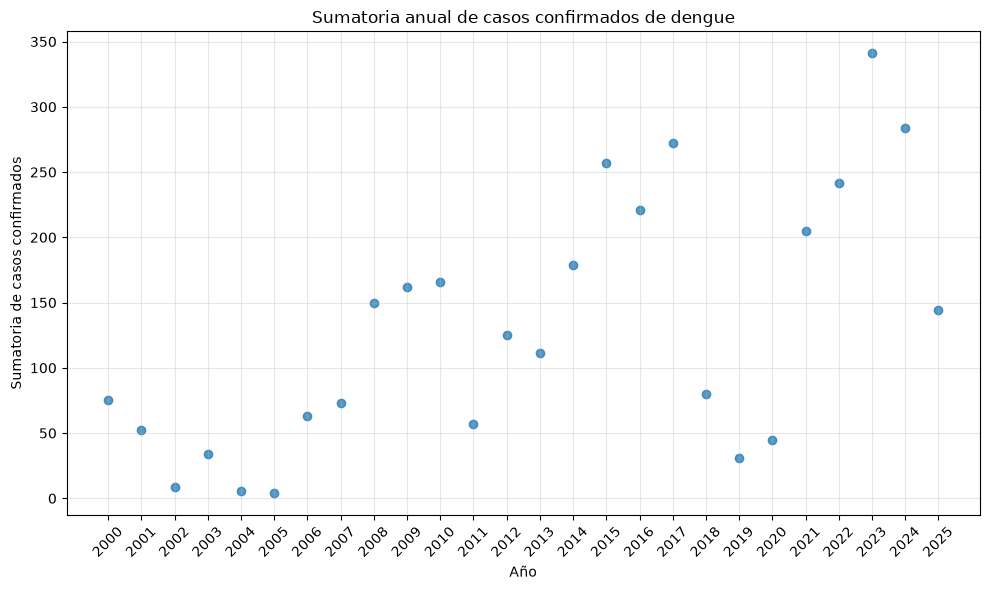

In [12]:
# Target transformado para reducir asimetría
df_etl['Casos_Log'] = np.log1p(df_etl['Casos_Confirmados'])
df_etl['Casos_Log'].dtype
# Nueva observación del gráfico
cantidad_casos_anual("Casos_Log")

Se observa una ligera mejora en la distribución de los datos y una 'tendencia' de crecimiento más clara, asi también los datos no se ven tan separados con la transformación a escala logarítmica

### Componente Autorregresivo: Utilizar Casos_Log como feature
Esta nueva variable objetivo transformada se usará como variable predictiva al mismo tiempo, el objetivo de esto es que el modelo pueda observar la tendencia de los datos, si crecen o están cayendo.

- Casos_Log pasados le dicen al modelo dónde está parada la curva hoy y con qué tendencia viene.
- Clima + Niño 1+2 le dicen al modelo si el ambiente va a acelerar o frenar esa curva.

In [13]:
FEATURES = [
    'Casos_Log',       # Historial reciente de casos (autorregresivo)
    'Precipitacion',
    'Temp_Max',
    'Temp_Min',
    'TSM_Nino12',
    'Anomalia_Nino12',
    'semana_sin',
    'semana_cos'
]
# Los valores de la variable objetivo se quedarán como valores logarítmicos puros
df_etl['Target_Log'] = df_etl['Casos_Log']
TARGET = 'Target_Log'
VENTANA_TIEMPO = 4  # 4 semanas (1 mes epidemiológico: ciclo de incubación y transmisión)

## Función de transformación: De matrices a tensores
Hasta el momento, el dataset sigue siendo una matriz de 2 dimeniones (filas x columnas), en CNN 1D se utilizan tensores, que son objetos tridimensionales compuestos de 3 partes: Muestras, Pasos de tiempo y caracterísiticas:

- Muestras: Cada pedazo separado por bloques de tiempo
- Pasos de tiempo: Cada semana del bloque de tiempo
- Características: Las variables meteorológicas utilizadas y el historial de casos.

La siguiente función convertirá todo el conjunto de entrenamiento y prueba en tensores

In [14]:
# 2. EL MOTOR DE TRANSFORMACIÓN (Ventana Deslizante)
def transformar_a_tensor_3d(df, columnas_features, columna_target, semanas_historial):
    X, y = [], []

    # Extraemos solo los valores numéricos como matrices de NumPy
    valores_features = df[columnas_features].values
    valores_target = df[columna_target].values

    # Iteramos limitando el final para no buscar datos que no existen
    for i in range(len(df) - semanas_historial):

        # X: Cortamos un "bloque" de tiempo (ej. de la semana 1 a la 3)
        bloque_x = valores_features[i : i + semanas_historial]

        # Y: Tomamos el valor objetivo de la semana SIGUIENTE al bloque (ej. semana 4)
        valor_y = valores_target[i + semanas_historial]

        X.append(bloque_x)
        y.append(valor_y)

    # Convertimos las listas resultantes a Tensores de NumPy
    return np.array(X), np.array(y)


# ***Muestras***:
## Cada Matriz de distinto color

# ***Pasos_de_Tiempo***:
## Cada fila de cada matriz

# ***Características***:
## Cada columna de cada matriz

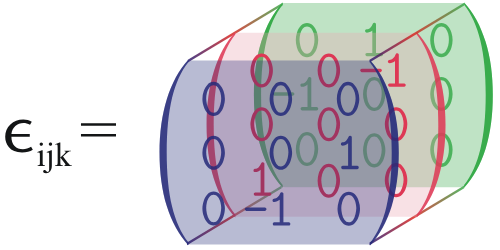

## Evitando la fuga de datos: División de datos 
Se separan en train y test los datos antes de ajustar con StandardScaler(), de este modo se evitará la fuga de datos, puesto que el escalado utiliza la media y la desviación estándar para escalar todos los datos, de este modo se evitaría que parte del comportamiento del test se presente en train.

In [15]:
from sklearn.preprocessing import StandardScaler

# 1. Corte cronológico 80/20 sobre el DataFrame 2D
corte = int(len(df_etl) * 0.8)
df_train = df_etl.iloc[:corte].copy()
# Incluimos las últimas VENTANA_TIEMPO filas de train al inicio de test
# para no perder las primeras predicciones del bloque de prueba
df_test = df_etl.iloc[corte - VENTANA_TIEMPO:].copy()
# 2. Escalado ajustado SOLO con train
scaler = StandardScaler()
df_train[FEATURES] = scaler.fit_transform(df_train[FEATURES])
df_test[FEATURES] = scaler.transform(df_test[FEATURES])
print(f"Conjunto de entrenamiento: {df_train.shape}")
display(df_train[FEATURES])
print(f"Conjunto de prueba: {df_test.shape}")
display(df_test[FEATURES])

Conjunto de entrenamiento: (1084, 12)


,Casos_Log,Precipitacion,Temp_Max,Temp_Min,TSM_Nino12,Anomalia_Nino12,semana_sin,semana_cos
0,-1.017329,-0.319154,0.240847,0.014157,0.078954,-0.395400,0.161702,1.418150
1,-1.017329,-0.325301,0.415680,0.057332,0.214090,-0.623995,0.328865,1.387528
2,-1.017329,-0.325301,0.822166,0.622531,0.259135,-0.852589,0.491151,1.336983
3,-1.017329,0.117295,0.354488,1.050355,0.439317,-0.852589,0.646209,1.267248
4,-1.017329,0.264827,0.647333,1.152405,0.844725,-0.395400,0.791794,1.179333
...,...,...,...,...,...,...,...,...
1079,-1.017329,-0.325301,-0.589609,-1.477339,-1.497633,-0.852589,-1.373561,-0.348293
1080,-1.017329,-0.288418,-0.257427,-1.394915,-1.407542,-0.623995,-1.406800,-0.181120
1081,-0.666080,-0.325301,-0.187494,-1.065215,-1.407542,-0.623995,-1.419780,-0.011151
1082,-1.017329,-0.325301,-0.183123,-1.080915,-1.452587,-0.852589,-1.412314,0.159151


Conjunto de prueba: (280, 12)


,Casos_Log,Precipitacion,Temp_Max,Temp_Min,TSM_Nino12,Anomalia_Nino12,semana_sin,semana_cos
1076,-0.666080,-0.325301,-0.965500,-1.292865,-1.317451,-0.509698,-1.158527,-0.809247
1077,-1.017329,-0.325301,-0.781926,-1.563689,-1.407542,-0.738292,-1.248519,-0.664648
1078,-1.017329,-0.325301,-1.280199,-1.461639,-1.497633,-0.852589,-1.320545,-0.510251
1079,-1.017329,-0.325301,-0.589609,-1.477339,-1.497633,-0.852589,-1.373561,-0.348293
1080,-1.017329,-0.288418,-0.257427,-1.394915,-1.407542,-0.623995,-1.406800,-0.181120
...,...,...,...,...,...,...,...,...
1351,-0.314830,-0.325301,0.280184,-0.115367,-0.506635,-0.281103,-0.535496,1.325821
1352,-0.460612,0.227944,-0.082594,-0.554966,-0.416545,-0.281103,-0.374341,1.379882
1353,-0.314830,-0.208505,0.367601,0.002383,-0.371499,-0.509698,-0.207878,1.414132
1354,-0.201753,-0.325301,0.782829,-0.095742,-0.146273,-0.395400,-0.038520,1.428075


Una vez separados los datos, **se observa que las primeras 4 filas del conjunto de prueba son las últimas 4 filas del conjunto de entrenamiento**, el motivo es evitar la pérdida de registros:

En las líneas

```python
corte = int(len(df_etl) * 0.8) -> 1084 registros
df_train = df_etl.iloc[:corte].copy() -> filas 0 - 1083 
df_test = df_etl.iloc[corte - VENTANA_TIEMPO:].copy() -> filas 1080 - 1355
```

Esas 4 primeras filas sirven para formar el primer tensor `X_test[0]` y predecir `y_test[0]` (fila 1084). Esto no genera **data leakage** porque `scaler.fit_transform` se ajusta exclusivamente sobre `df_train` y las filas `1080..1083` nunca aparecen como objetivo en `y_test`.

### Transformación de train y test en tensores listos para CNN

In [16]:
# 3. EJECUCIÓN DE LA TRANSFORMACIÓN
X_train, y_train = transformar_a_tensor_3d(df_train, FEATURES, TARGET, VENTANA_TIEMPO)
X_test, y_test = transformar_a_tensor_3d(df_test, FEATURES, TARGET, VENTANA_TIEMPO)

# 4. VERIFICACIÓN DE LA ARQUITECTURA
print("--- ANÁLISIS DE DIMENSIONES DEL CONJUNTO DE ENTRENAMIENTO ---")
print(f"Dataframe Original 2D : {df_train[FEATURES].shape} -> (Filas totales, Columnas)")
print(f"Tensor X_train 3D para CNN  : {X_train.shape} -> (Muestras, Pasos_de_Tiempo, Características)")
print(f"Vector y_train de Etiquetas : {y_train.shape}  -> (Muestras,)")

print("\n--- ANÁLISIS DE DIMENSIONES DEL CONJUNTO DE PRUEBA ---")
print(f"Dataframe Original 2D : {df_test[FEATURES].shape} -> (Filas totales, Columnas)")
print(f"Tensor X_test 3D para CNN  : {X_test.shape} -> (Muestras, Pasos_de_Tiempo, Características)")
print(f"Vector y_test de Etiquetas : {y_test.shape}  -> (Muestras,)")

print("\n--- LO QUE VE LA RED NEURONAL EN LA MUESTRA 0 DE ENTRENAMIENTO ---")
print(f"Entrada X (Clima y Casos de las Semanas 1-{VENTANA_TIEMPO}):")
print(X_train[0])
print(f"Salida Esperada Y (Casos_Log en la Semana {VENTANA_TIEMPO + 1}): {y_train[0]}")

--- ANÁLISIS DE DIMENSIONES DEL CONJUNTO DE ENTRENAMIENTO ---
Dataframe Original 2D : (1084, 8) -> (Filas totales, Columnas)
Tensor X_train 3D para CNN  : (1080, 4, 8) -> (Muestras, Pasos_de_Tiempo, Características)
Vector y_train de Etiquetas : (1080,)  -> (Muestras,)

--- ANÁLISIS DE DIMENSIONES DEL CONJUNTO DE PRUEBA ---
Dataframe Original 2D : (276, 8) -> (Filas totales, Columnas)
Tensor X_test 3D para CNN  : (272, 4, 8) -> (Muestras, Pasos_de_Tiempo, Características)
Vector y_test de Etiquetas : (272,)  -> (Muestras,)

--- LO QUE VE LA RED NEURONAL EN LA MUESTRA 0 DE ENTRENAMIENTO ---
Entrada X (Clima y Casos de las Semanas 1-4):
[[-1.01732919 -0.31915362  0.24084683  0.01415749  0.078954   -0.39540049
   0.16170197  1.41815042]
 [-1.01732919 -0.32530079  0.41567973  0.0573324   0.21408999 -0.62399469
   0.32886498  1.38752776]
 [-1.01732919 -0.32530079  0.82216621  0.62253121  0.25913533 -0.85258889
   0.49115074  1.33698297]
 [-1.01732919  0.11729519  0.35448821  1.05035531  0.4

## Creación del Modelo CNN
Finalmente, luego de transformar los registros en objetos legibles para el modelo y separar los datos en entrenamiento y prueba, se procede con la creación de secuencia de capas del modelo

In [69]:
# Instalar tensorflow
%pip install tensorflow

^C
Note: you may need to restart the kernel to use updated packages.


In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Semilla global para reproducibilidad exacta de los pesos iniciales y lotes
tf.keras.utils.set_random_seed(13)

# 1. Definición de la Arquitectura CNN-1D Causal con Regularización L2
modelo_dengue = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),

    # CAPAS DE EXTRACCIÓN TEMPORAL CAUSAL (Sin MaxPooling para preservar la señal de la última semana t-1)
    Conv1D(filters=32, kernel_size=2, padding='causal', activation='relu', kernel_regularizer=l2(1e-3)),
    Conv1D(filters=16, kernel_size=2, padding='causal', activation='relu', kernel_regularizer=l2(1e-3)),

    # APLANAMIENTO
    Flatten(),

    # CAPA OCULTA DENSA REGULARIZADA (Reemplaza Dropout por L2 para no sesgar la escala lineal al aplicar expm1)
    Dense(32, activation='relu', kernel_regularizer=l2(1e-3)),

    # CAPA DE SALIDA LINEAL
    Dense(1, activation='linear')
])

# 2. Compilación del Modelo
modelo_dengue.compile(optimizer=Adam(learning_rate=0.001),
                      loss='mse',
                      metrics=['mae'])

# 3. Resumen de la red
modelo_dengue.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 4, 32)          │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4, 16)          │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴─────────────────────

## Entrenamiento Supervisado
Una vez creada la estructura de la red neuronal convolucional, se procede con el entrenamiento del modelo de aprendizaje profundo, este será entrenado de forma supervisada usando EarlyStopping, el cuál permite reconocer en qué epoch exacta el modelo empieza a memorizar (overfiting) en lugar de aprender. También se utiliza ReduceLROnPlanteau para ajustar la tasa de aprendizaje durante las iteraciones, siendo el factor=0.5 el que indica cuanto se reduce la tasa de aprendizaje cuando val_loss se estanca.

Iniciando el entrenamiento supervisado...
Entrenamiento finalizado en época 35 (mejor época restaurada: 15, loss=0.3750, val_loss=0.5399, val_mae=0.5621)


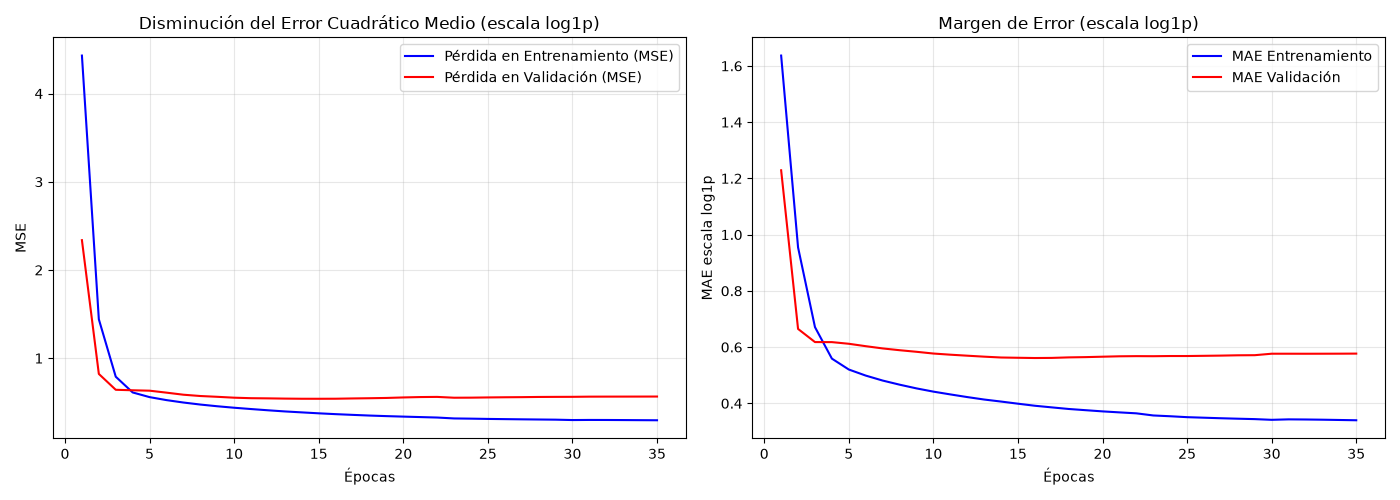

In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

# 1. Configuración de Callbacks (EarlyStopping + Reducción adaptativa de Learning Rate)
supervisor_entrenamiento = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

reductor_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    min_lr=1e-5,
    verbose=1
)

print("Iniciando el entrenamiento supervisado...")

# 2. Entrenamiento con batch_size=32 y validation_split=0.1
# Con validation_split=0.1 el brote del Niño Costero 2017 permanece dentro del 90% de entrenamiento
historial = modelo_dengue.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.1,
    callbacks=[supervisor_entrenamiento, reductor_lr],
    verbose=1
)

# 3. GRAFICANDO LA CURVA DE APRENDIZAJE
perdida_train = historial.history['loss']
perdida_val = historial.history['val_loss']
mae_train = historial.history['mae']
mae_val = historial.history['val_mae']
epocas = range(1, len(perdida_train) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epocas, perdida_train, 'b-', label='Pérdida en Entrenamiento (MSE)')
plt.plot(epocas, perdida_val, 'r-', label='Pérdida en Validación (MSE)')
plt.title('Disminución del Error Cuadrático Medio (escala log1p)')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epocas, mae_train, 'b-', label='MAE Entrenamiento')
plt.plot(epocas, mae_val, 'r-', label='MAE Validación')
plt.title('Margen de Error (escala log1p)')
plt.xlabel('Épocas')
plt.ylabel('MAE escala log1p')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Destransformar predicciones
Luego del entrenamiento se procede a destransformar las predicciones del modelo para compararlas con los resultados verdaderos (y_pred_casos)

--- EVALUACIÓN EN EL CONJUNTO DE PRUEBA (ESCALA REAL DE CASOS) ---
MAE en casos reales:  119.49 casos
RMSE en casos reales: 343.50 casos
Coeficiente R²:       0.9037


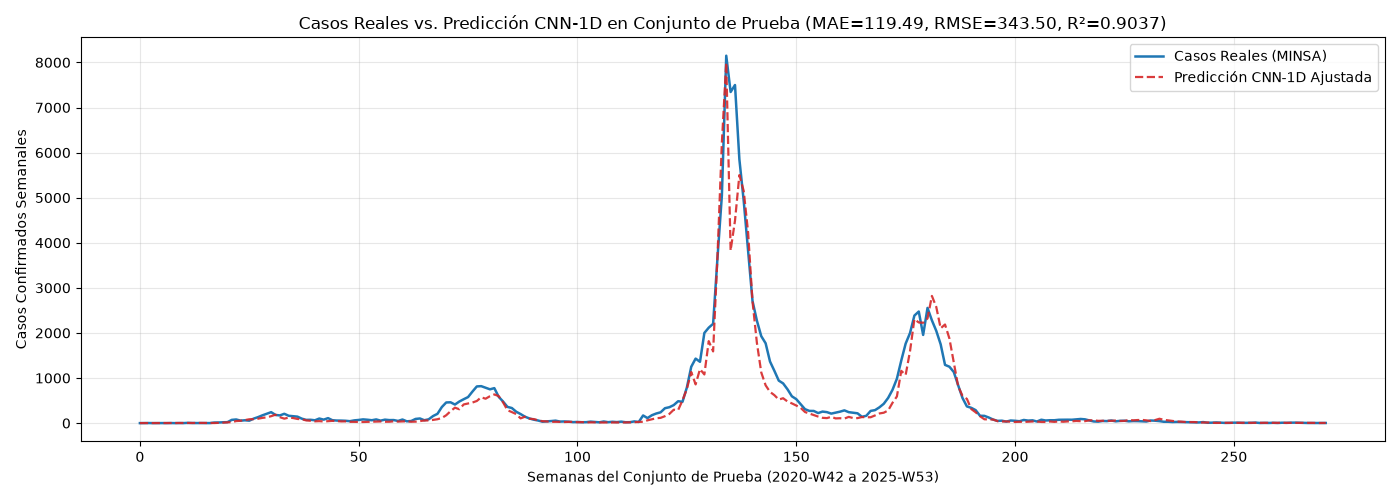

In [19]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Predicción en escala logarítmica y retorno a escala real de casos
y_pred_log = modelo_dengue.predict(X_test, verbose=0).ravel()
y_pred_casos = np.clip(np.expm1(y_pred_log), 0, None)
y_test_casos = np.expm1(y_test)

mae_real = mean_absolute_error(y_test_casos, y_pred_casos)
rmse_real = root_mean_squared_error(y_test_casos, y_pred_casos)
r2_real = r2_score(y_test_casos, y_pred_casos)

print("--- EVALUACIÓN EN EL CONJUNTO DE PRUEBA (ESCALA REAL DE CASOS) ---")
print(f"MAE en casos reales:  {mae_real:.2f} casos")
print(f"RMSE en casos reales: {rmse_real:.2f} casos")
print(f"Coeficiente R²:       {r2_real:.4f}")

plt.figure(figsize=(14, 5))
plt.plot(y_test_casos, label='Casos Reales (MINSA)', color='tab:blue', linewidth=1.8)
plt.plot(y_pred_casos, label='Predicción CNN-1D Ajustada', color='tab:red', linestyle='--', linewidth=1.6, alpha=0.9)
plt.title(f'Casos Reales vs. Predicción CNN-1D en Conjunto de Prueba (MAE={mae_real:.2f}, RMSE={rmse_real:.2f}, R²={r2_real:.4f})')
plt.xlabel('Semanas del Conjunto de Prueba (2020-W42 a 2025-W53)')
plt.ylabel('Casos Confirmados Semanales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Interpretación de los resultados


## MAE = 119.49

El error absoluto medio indica el promedio de las diferencias absolutas entre los valores predichos y los reales, para este proyecto, el resultado indica que, en una semana típica, el modelo llega a equivocarse en ±119 casos confirmados (por exceso o por defecto); para los centros médicos en Piura, esto sería de utilidad para destinar equipamiento para una mayor cantidad de casos de dengue que las esperadas.

## RMSE = 343.50

La Ráiz del Error Cuadrático Medio resalta más los errores grandes que los pequeños, el valor de esta métrica es mayor que MAE por los brotes históricos que ocurrieron en 2023 (Ver pico más alto del gráfico Casos Reals vs Predicción CNN-1D). En una anterior iteración, el resutlado del RMSE fue de 666.52, el cambio para reducirlo fue el parámetro validation_split  = 0.1 en el entrenamiento, dejando así que los periodos del año 2017 donde hubo picos de casos de dengue confirmados pudieran ser manejados por el modelo.

## R² = 0.9037 (90.37%)

El coeficiente de Determinación mide que tan bien el modelo puede manejar la variabilidad de los datos, el 90.37% obtenido en este proyecto puede visualizarse geométricamente en la gráfica que compara los resultados predichos versus reales donde la curva de CNN-1D sigue la forma real de los casos confirmados en una gran parte de este.